# ReadData: 生データの読み込みとイベント同期

SMILE-2+ の生データは**検出器(ボード)ごとに別ファイル**です。

| ファイル | 中身 |
|---|---|
| `uTPC_anode{1..3}_*.raw` | TPC アノード 3 ボード: ヒットしたストリップ・クロック(エンコーダ)と FADC 波形 4 ch ずつ |
| `uTPC_cathode{1..3}_*.raw` | TPC カソード 3 ボード: 同上 |
| `HA{id}_*.raw` | シンチレータ(HA)モジュール 18 台: PMT 6 本 × 4 ch の ADC |

`ReadData` はこれらを 1 イベントずつ読み、**全ボードのイベント番号がそろうまで遅れているボードを読み進めて**同期させます
(そろうまでに読み飛ばしが起きたイベントは `IDcheck_Loopback` フラグが立ちます)。
SMILE_tool_box の `RawRead2p` に相当します。

> 実行時間の大部分は生データの読み込みです。ネットワーク越しの場所から読むと数倍〜10 倍遅くなるので、
> データは手元のディスクにコピーして使うことをおすすめします(1 節)。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `data_dir` | `.../Per02_ETCC` | 生データのディレクトリ |
| `reverse_TPC` | `True` | TPC のストリップ番号の向きを反転する(SMILE-2+ の配線に合わせる) |
| `TPC_Only` | `False` | `True` なら HA を読まない |

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/


data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

In [3]:
# ReadData -> RawTreeWriter の出力(tutorials/cache/ に保存し、他のモジュールのノートブックと共有)
RAW = tu.get_raw("Per02", 5000)
INFO = tu.raw_info(RAW)
INFO

Per02_raw_5000.root は既にあるので再実行しません(overwrite=True で作り直し)


{'anode_ids': [1, 2, 3],
 'cathode_ids': [1, 2, 3],
 'ha_ids': [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]}

## 3. TPC のヒット

全イベントのヒットを積算したヒットマップ(横軸 ストリップ番号 0–383、縦軸 ドリフト方向のクロック)と、1 イベントの飛跡です。
アノードとカソードはそれぞれ x, y 方向のストリップ(ピッチ 0.8 mm)で、クロックがドリフト時間(z 方向)になります。

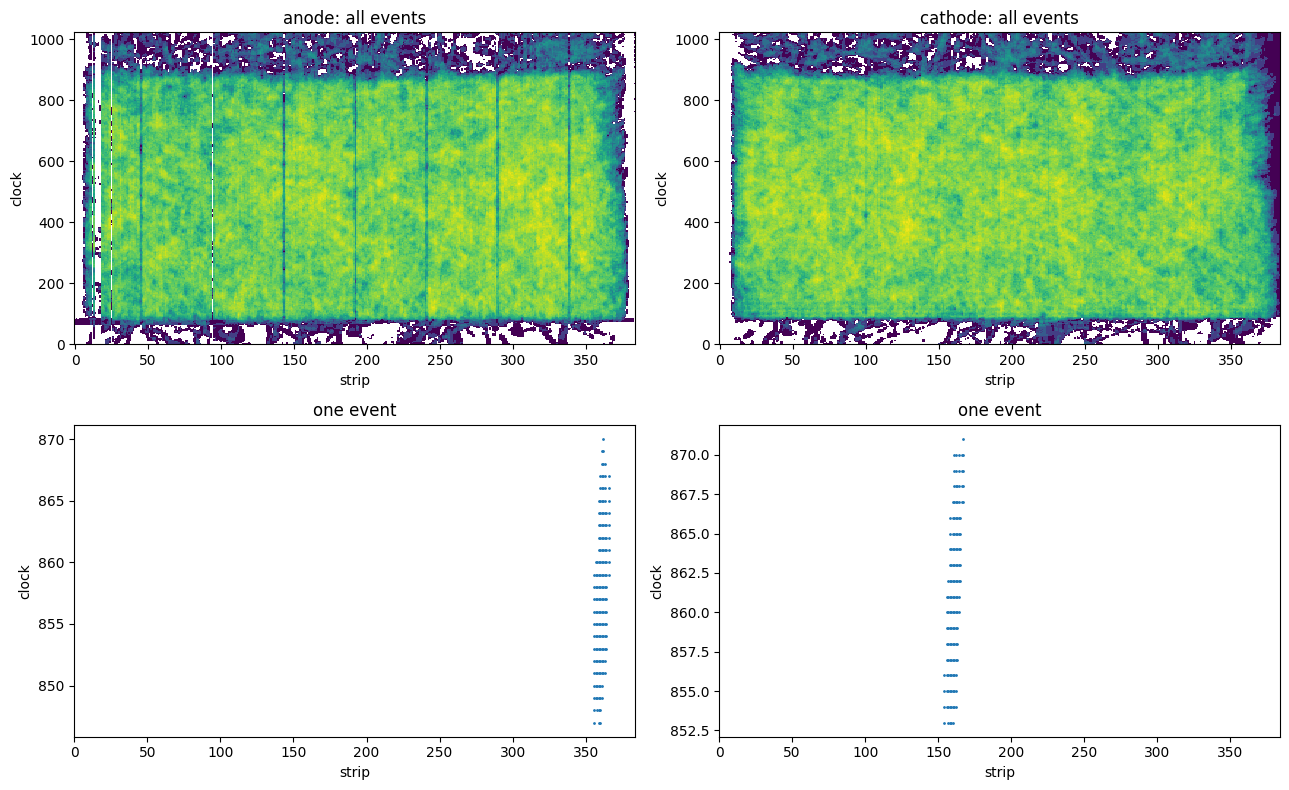

In [4]:
d = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW))
hA = d.Histo2D(("hA", "", 384, -0.5, 383.5, 1024, -0.5, 1023.5), "hit_a_strip", "hit_a_clock")
hC = d.Histo2D(("hC", "", 384, -0.5, 383.5, 1024, -0.5, 1023.5), "hit_c_strip", "hit_c_clock")
e = list(tu.iter_raw(RAW, ["hit_a_strip", "hit_a_clock", "hit_c_strip", "hit_c_clock"], n=20))[-1]

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for k, (h, side) in enumerate([(hA, "a"), (hC, "c")]):
    v, xe, ye = tu.th2_to_numpy(h.GetPtr())
    ax[0, k].pcolormesh(xe, ye, v.T, norm="log"); ax[0, k].set_title(f"{'anode' if side == 'a' else 'cathode'}: all events")
    ax[1, k].plot(e[f"hit_{side}_strip"], e[f"hit_{side}_clock"], ".", ms=2)
    ax[1, k].set_title("one event"); ax[1, k].set_xlim(0, 384)
    for a in ax[:, k]: a.set_xlabel("strip"); a.set_ylabel("clock")
fig.tight_layout(); plt.show()

## 4. TPC の FADC 波形

FADC はボードごとに 4 ch あり、各 ch は 32 ストリップ分の信号の和です(アノード 12 ch、カソード 12 ch)。
アノード ch 0 とカソード ch 0 の波形を重ね描きします(横軸 サンプル番号、縦軸 ADC 値)。これを `CalcFADC` が電荷に変換します。

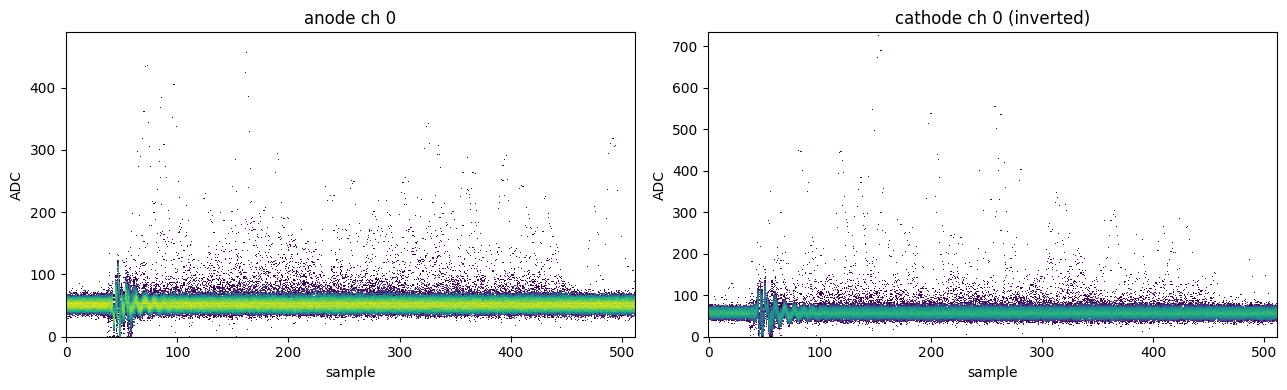

In [5]:
acc = {0: np.zeros((512, 1024)), 12: np.zeros((512, 1024))}
for ch, w in tu.raw_waveforms(RAW, n=2000):
    for c in acc:
        if c in ch:
            y = np.clip(w[list(ch).index(c)].astype(int), 0, 1023)
            acc[c][np.arange(512), y] += 1
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (c, lab) in zip(ax, [(0, "anode ch 0"), (12, "cathode ch 0 (inverted)")]):
    v = acc[c]; iy = np.nonzero(v.sum(0))[0]
    a.pcolormesh(np.arange(513) - 0.5, np.arange(1025) - 0.5, v.T, norm="log")
    a.set_ylim(iy.min(), iy.max() + 1); a.set_title(lab); a.set_xlabel("sample"); a.set_ylabel("ADC")
fig.tight_layout(); plt.show()

## 5. HA の ADC

HA01 モジュールの 24 ch(PMT 6 本 × 4 ch)の ADC 分布を、エラービットが立っていないもの(OK)と立っているもの(NG)に分けて描きます。

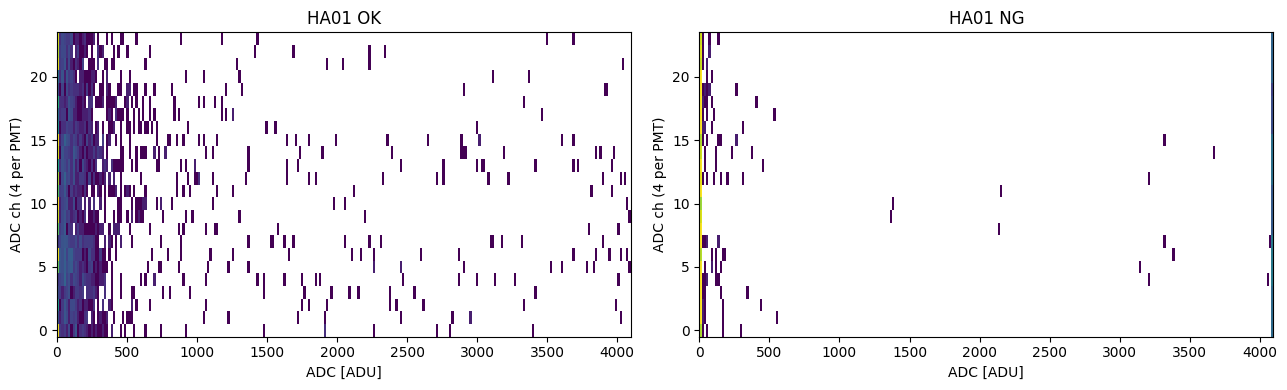

In [6]:
adc, err = tu.raw_ha(RAW)
ha = INFO["ha_ids"].index(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, sel, lab in [(ax[0], ~err[:, ha], "OK"), (ax[1], err[:, ha], "NG")]:
    ch = np.broadcast_to(np.arange(24), adc[:, ha].shape)
    a.hist2d(adc[:, ha][sel], ch[sel], bins=[256, 24], range=[[0, 4096], [-0.5, 23.5]], cmin=1, norm="log")
    a.set_title(f"HA01 {lab}"); a.set_xlabel("ADC [ADU]"); a.set_ylabel("ADC ch (4 per PMT)")
fig.tight_layout(); plt.show()